# Integrating flexural and tensile curves

Calculation of curve areas used in the Bouligand composite manuscript analysis. The Excel workbook here contains generated example data.

## Curve area

$$A_f=\int_{\varepsilon_{\mathrm{first}}}^{\varepsilon_{\mathrm{peak}}}\sigma_f\,d\varepsilon,\qquad w_t=\int_{\varepsilon_{\mathrm{first}}}^{\varepsilon_{\mathrm{last}}}\sigma_t\,d\varepsilon.$$

Stress in MPa and dimensionless strain give MJ/m³. Flexural area is integrated to peak stress; tensile work is integrated to the last recorded point.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#233744", "text.color": "#233744",
    "axes.edgecolor": "#9aabb2", "figure.facecolor": "white",
    "savefig.facecolor": "white", "svg.fonttype": "none",
})
colors = ["#236b73", "#bb7639", "#5d6eaa"]
Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

from scipy.integrate import trapezoid

In [2]:
workbook = Path("inputs/composite_example.xlsx")
measurements = pd.read_excel(workbook, sheet_name="Measurements")
dimensions = pd.read_excel(workbook, sheet_name="Dimensions", usecols="A:G")
dimensions = dimensions.set_index("specimen", verify_integrity=True)

curves, cleaning = {}, []
for specimen, raw in measurements.groupby("specimen", sort=False):
    d = dimensions.loc[specimen]
    if set(raw["test"]) != {d["test"]}:
        raise ValueError(f"Test labels disagree for {specimen}")
    if min(d["width_mm"], d["thickness_mm"], d["length_mm"]) <= 0:
        raise ValueError(f"Invalid dimensions for {specimen}")
    pair = raw[["displacement_mm", "force_N"]].apply(pd.to_numeric, errors="coerce")
    pair = pair.replace([np.inf, -np.inf], np.nan).dropna()
    displacement, force = pair.to_numpy().T
    width, thickness, length = d[["width_mm", "thickness_mm", "length_mm"]]
    if d["test"] == "flexural":
        strain = 6 * displacement * thickness / length**2
        stress = 3 * force * length / (2 * width * thickness**2)
    elif d["test"] == "tensile":
        strain = displacement / length
        stress = force / (width * thickness)
    else:
        raise ValueError(f"Unknown test: {d['test']}")
    if len(strain) < 3 or np.any(np.diff(strain) <= 0):
        raise ValueError(f"Expected an increasing loading curve for {specimen}")
    curves[specimen] = pd.DataFrame({"strain": strain, "stress_MPa": stress})
    cleaning.append({"specimen": specimen, "retained": len(pair), "missing_pairs": len(raw) - len(pair)})

In [3]:
def curve_area(curve, endpoint):
    strain, stress = curve[["strain", "stress_MPa"]].to_numpy().T
    stop = int(np.argmax(stress)) + 1 if endpoint == "peak" else len(strain)
    if endpoint not in {"peak", "last"}:
        raise ValueError("Endpoint must be peak or last")
    return float(trapezoid(stress[:stop], strain[:stop])), stop

areas, stops, rows = {}, {}, []
for name, curve in curves.items():
    test = dimensions.loc[name, "test"]
    endpoint = "peak" if test == "flexural" else "last"
    area, stop = curve_area(curve, endpoint)
    areas[name], stops[name] = area, stop
    rows.append({"specimen": name, "test": test, "endpoint": endpoint,
                 "area_MJ_m3": area, "end_strain": curve["strain"].iloc[stop - 1]})
integrals = pd.DataFrame(rows)
summary = integrals.groupby("test")["area_MJ_m3"].agg(n="count", mean="mean", sd="std")
integrals.to_csv("results/curve_areas.csv", index=False)
summary.to_csv("results/area_summary.csv")
display(summary.rename(columns={"mean": "mean (MJ/m³)", "sd": "sample SD (MJ/m³)"}).round(4))

,n,mean (MJ/m³),sample SD (MJ/m³)
test,,,
flexural,3,1.7779,0.0976
tensile,3,2.2591,0.1240


## Integrated regions

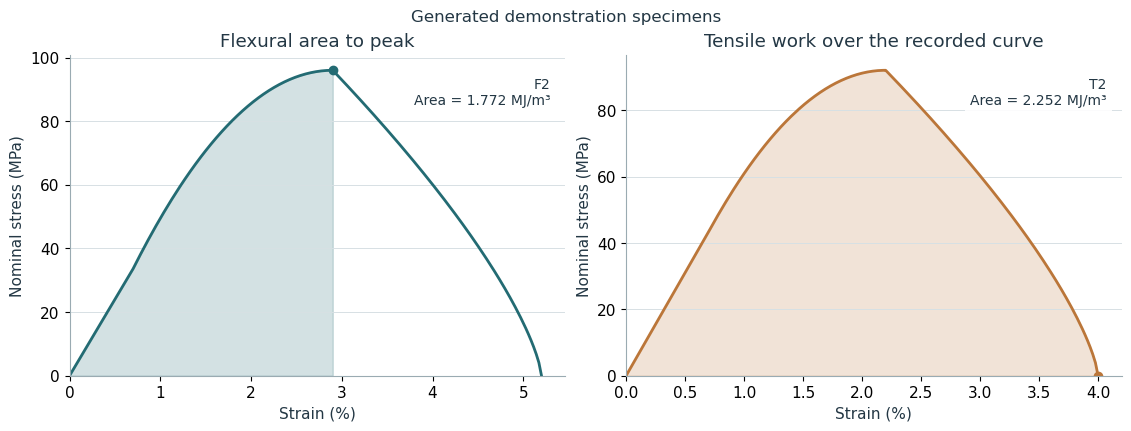

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11.2, 4.2), layout="constrained")
for a, name, color, title in zip(ax, ["F2", "T2"], colors,
                                ["Flexural area to peak", "Tensile work over the recorded curve"]):
    curve, stop = curves[name], stops[name]
    strain, stress = curve[["strain", "stress_MPa"]].to_numpy().T
    a.plot(100 * strain, stress, color=color, lw=2)
    a.fill_between(100 * strain[:stop], stress[:stop], color=color, alpha=0.20)
    a.plot(100 * strain[stop - 1], stress[stop - 1], "o", color=color, ms=6)
    a.text(0.97, 0.93, f"{name}\nArea = {areas[name]:.3f} MJ/m³", transform=a.transAxes,
           ha="right", va="top", fontsize=10,
           bbox=dict(facecolor="white", edgecolor="none", alpha=0.9))
    a.set(xlabel="Strain (%)", ylabel="Nominal stress (MPa)", title=title,
          xlim=(0, None), ylim=(0, None))
    a.grid(axis="y", color="#d7e0e4", lw=0.7)
fig.suptitle("Generated demonstration specimens", fontsize=12)
fig.savefig("figures/curve_integration.png", dpi=180, bbox_inches="tight")
fig.savefig("figures/curve_integration.svg", bbox_inches="tight")
plt.show()